In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

### Hamiltonian
the Hamiltonian with two magnetic sublattices ( $\mathbf{S}_1$ and $\mathbf{S}_2$ ) is 

$ \mathcal{H}_0 = n J \mathbf{S}_1\cdot\mathbf{S}_2 + n\mathbf{D}\cdot\left(\mathbf{S}_1\times\mathbf{S}_2\right) - K_a\left(S^2_{1X}+S^2_{2X}\right) - K_c\left(S^2_{1Z}+S^2_{2Z}\right)$

when applying THz pulses, the magnetic field components of the THz pulses ( $\mathbf{H}_{\text{A}}(t,\tau)$ and $\mathbf{H}_{\text{B}}(t)$ ) will couple with two spins, described by the Zeeman term : 

$ \mathcal{H}_{\text{zeeman}} = -\gamma_0\left[\mathbf{H}_{\text{A}}(t,\tau) + \mathbf{H}_{\text{B}}(t)\right]\cdot\left(\mathbf{S}_1 + \mathbf{S}_2\right)$

These two magnetic field components ( $\mathbf{H}_{\text{A}}(t,\tau)$ and $\mathbf{H}_{\text{B}}(t)$ ) are the second derivatives of a Gaussian function which ensures that the temporal integration of pulses reduces to zero.

### Ground State ( Classical Analysis )
Ground state is the lowest-energy configuration. 
- the exchange term $n J \mathbf{S}_1\cdot\mathbf{S}_2$ wants the two spins align oppositely
- the DM term $n\mathbf{D}\cdot\left(\mathbf{S}_1\times\mathbf{S}_2\right)$ wants $\mathbf{S}_1\times\mathbf{S}_2$ to be in the opposite direction to the $\mathbf{D}$, since $\mathbf{D}$ only has positive y component, $\mathbf{S}_1\times\mathbf{S}_2$ should have a negative y component
- the anisotropic term $- K_a\left(S^2_{1a}+S^2_{2a}\right)$ want the two spins has non-zero x-component
- the anisotropic term $- K_c\left(S^2_{1c}+S^2_{2c}\right)$ want the two spins has non-zero z-component

Overall, we can find that in the ground state, the two spins are in the XOZ plane ———— y component is zero ———— so we can get the energy as a function 

$$ \lang H\rang = n J \left(S_{1a}S_{2a} + S_{1c}S_{2c}\right) + nD(S_{1c}S_{2a} - S_{1a}S_{2c}) - K_a\left(S^2_{1a}+S^2_{2a}\right) - K_c\left(S^2_{1c}+S^2_{2c}\right)$$

with $S^2_{1a} + S^2_{1c} = S^2$ and $S^2_{2a} + S^2_{2c} = S^2$ as the constraints ( Lagrangian multiplier ).

We can make the canted-antiferromagnetic ansatz : $S_{1a} = -S_{2a}$ while $S_{1c} = S_{2c}$, we can introduce the canted angle $\beta_0$ that $S_{1a} = -S_{2a} = S\cos\beta_0$ and $S_{1c} = S_{2c} = S\sin\beta_0$, plug into $\lang H\rang$ and we can get

$$ \lang H\rang = - S^2\left[ (nJ + K_a - K_c)\cos(2\beta_0) + n D \sin(2\beta_0) \right] + \text{ const }$$

in ground state, $\lang H\rang$ should be at minimum with respect to $\beta_0$, so we have

$$ \tan(2\beta_0) = \frac{nD}{nJ + K_a - K_c} $$

canted angle $\beta_0$ is small since $J \gg D \gg K_a,K_c$

In [19]:
# parameters set up
Stot = 5/2 # dimensionless
nn = 6
Jex = 4.6 # meV
Da = 0
Db = 0.1066 # meV # Dvec only has non-zero y-component ( along b axis )
Dc = 0
Ka = 0.00905 # meV
Tk = 15 # Kelvin : 15 / 60 / 110 / 160
Kc = 0.9847 / (Tk + 62.38) + 0.00265 # meV

# canted angle
beta0 = 0.5 * np.arctan2(nn * Db, nn * Jex + Ka - Kc)

print("the canted angle is beta0 = ", beta0 * 180 / np.pi, " deg")
print("is the canted angle small enough to use the small angle approximation ? ", beta0 < 0.1 * np.pi)

the canted angle is beta0 =  0.6639170079686794  deg
is the canted angle small enough to use the small angle approximation ?  True


### time scales
1 THz = 10^12 Hz

1 ps = 10^-12 s

1 fs = 10^-15 s

qFM mode : frequency 0.38 THz or time period 2.63 x 10^-12 s = 2.63 ps

qAFM mode : frequency 0.67 THz or time period 1.49 x 10^-12 s = 1.49 ps

In [3]:
# dict for Hamiltonian parameters
Ham_params = {
    "nn": nn,
    "Stot": Stot,
    "Jex": Jex,
    "Dvec": np.array([Da, Db, Dc]),
    "Kvec": np.array([Ka, 0.0, Kc]),
}

In [4]:
Ham_params["Dvec"]

array([0.    , 0.1066, 0.    ])

### effective magnetic field for each spin

In [18]:
# function to compute effective magnetic fields without external field ( HA = HB = 0 )
# S1 : spin vector of sublattice A
# S2 : spin vector of sublattice B
# params : dict of parameters

# returns : H1_eff, H2_eff : effective magnetic fields for sublattice A and B, respectively

def effective_fields_woH(S1, S2, Ham_params):
  # unpack parameters
  nn = Ham_params["nn"]
  Jex = Ham_params["Jex"]
  Da, Db, Dc = Ham_params["Dvec"]
  Ka, Kb, Kc = Ham_params["Kvec"]

  # derivation : dH/dS1
  dHam_dS1X = nn * Jex * S2[0] + nn * (Dc * S2[1] - Db * S2[2]) - 2 * Ka * S1[0]
  dHam_dS1Y = nn * Jex * S2[1] + nn * (Da * S2[2] - Dc * S2[0]) - 2 * Kb * S1[1]
  dHam_dS1Z = nn * Jex * S2[2] + nn * (Db * S2[0] - Da * S2[1]) - 2 * Kc * S1[2]

  # derivation : dH/dS2
  dHam_dS2X = nn * Jex * S1[0] - nn * (Dc * S1[1] - Db * S1[2]) - 2 * Ka * S2[0]
  dHam_dS2Y = nn * Jex * S1[1] - nn * (Da * S1[2] - Dc * S1[0]) - 2 * Kb * S2[1]
  dHam_dS2Z = nn * Jex * S1[2] - nn * (Db * S1[0] - Da * S1[1]) - 2 * Kc * S2[2]

  # effective magnetic fields
  H1_eff = np.array([-dHam_dS1X, -dHam_dS1Y, -dHam_dS1Z])
  H2_eff = np.array([-dHam_dS2X, -dHam_dS2Y, -dHam_dS2Z])

  return H1_eff, H2_eff

### Pulse function for THz pulse

In [6]:
# pulse function for the external magnetic field
# The normalized Gaussian is g(t) = exp(-(t-t0)^2/(2*sigma^2)) / (sqrt(2*pi)*sigma).
# Its second derivative is used so that the pulse has zero time integral.
def gaussian_second_derivative(t, t0, sigma):
  if sigma <= 0:
    raise ValueError("sigma must be positive")

  tdiff = t - t0
  return ((tdiff ** 2 - sigma ** 2) / (np.sqrt(2 * np.pi) * sigma ** 5) 
          * np.exp(-(tdiff ** 2) / (2 * sigma ** 2)))

# same as gaussian_second_derivative function, but allow for user to change peak value
def d2gdt2_pulse(t, t0, sigma, h_peak):
  """ 
      Second-derivative Gaussian THz magnetic-field pulse.
      h_peak is the field value at t = t0.  
      The returned waveform is -h_peak*sqrt(2*pi)*sigma^3 times the normalized Gaussian second derivative.
  """
  # pulse = -h_peak * np.sqrt(2 * np.pi) * sigma ** 3 * gaussian_second_derivative(t, t0, sigma)
  tdiff = t - t0
  pulse = h_peak * (1 - (tdiff ** 2) / (sigma ** 2)) * np.exp(-(tdiff ** 2) / (2 * sigma ** 2))

  return pulse

# generate two THz magnetic-field pulses 
# return one 3d-vector H(t) = [Hx(t), Hy(t), Hz(t)] = H_A(t) + H_B(t)
def two_THz_pulses(t, pulse_params, pulse_func=d2gdt2_pulse):
  """
    Return the vector field H_A(t) + H_B(t) for a two-pulse sequence.

    pulse_params[label] : ( label = "A" or "B" )
        - shape_params (arguments for pulse_func)
        - linear polarization (a nonzero vector in the a, b, c basis)
        - state: "on"/1 or "off"/0
    
    pulse_func(t, **shape_params) returns the scalar temporal field amplitude.
  """

  H_total = np.zeros(3)
  
  for label in ("A", "B"):
    pulse = pulse_params[label]
    state = pulse.get("state", "on")
    if state in ("off", 0, False):
      continue
    if state not in ("on", 1, True):
      raise ValueError(f"Pulse {label} state must be 'on'/'off' or 1/0")

    # only consider linear polarization for now
    linpol = np.asarray(pulse["polarization"], dtype=float) 

    linpol_norm = np.linalg.norm(linpol)
    if linpol.shape != (3,) or linpol_norm == 0:
      raise ValueError(f"Pulse {label} linear polarization must be a nonzero length-3 vector")

    hlist = pulse_func(t, **pulse["shape_params"])
    H_total += hlist * linpol / linpol_norm
  
  return H_total

### Pulse parameters in the paper
From Fig.S1(b) in the "magnon upconversion" paper, the time-delay $\tau$ between pulse A and pulse B is around 

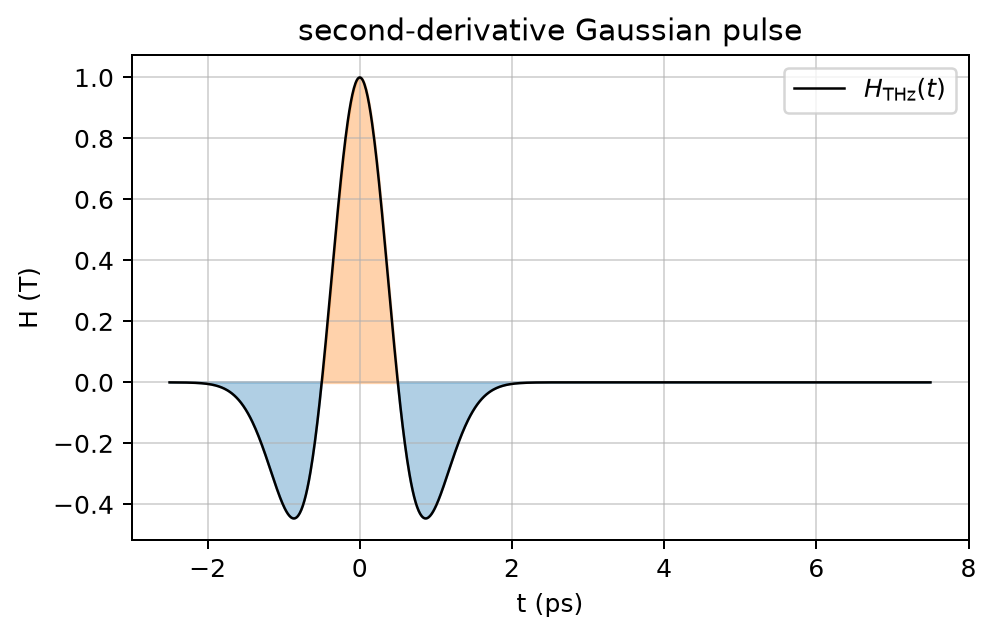

In [12]:
# Plot THz_gaussian_pulse over time grid
sigma = 0.5
t0 = 0.0 * sigma
# halfwidth = 5 * sigma
start_time = t0 - 5 * sigma
end_time = t0 + 15 * sigma
h_peak = 1
num_points = 1000

tlist = np.linspace(start_time, end_time, num_points)
hlist = d2gdt2_pulse(tlist, t0, sigma, h_peak)

fig, ax = plt.subplots(figsize=(6, 3.5), dpi=180)

ax.fill_between(tlist, hlist, 0, where=(hlist >= 0), interpolate=True,
                color="tab:orange", alpha=0.35, label=None)
ax.fill_between(tlist, hlist, 0, where=(hlist < 0), interpolate=True,
                color="tab:blue", alpha=0.35, label=None)

ax.plot(tlist, hlist, color="black", linewidth=1, label=r"$H_{\mathrm{THz}}(t)$")
# ax.axhline(0, color="black", linewitsteph=0.8)
# ax.axvline(t0, color="gray", linestyle="--", linewitsteph=1, label=r"$t_0$")

ax.set_xlabel("t (ps)")
ax.set_ylabel(r"H (T)")
ax.set_title("second-derivative Gaussian pulse")
ax.grid(alpha=0.5)
ax.legend()

### Fourier spectrum of the THz pulse

In [13]:
# Fourier transform of the pulse sampled in the previous cell.
# tlist is in ps, therefore frequency is in THz.
tstep = tlist[1] - tlist[0]
positive_freqlist = np.fft.rfftfreq(tlist.size, d=tstep)

spectrum = np.fft.rfft(hlist)
spectral_amplitude = np.abs(spectrum)
spectral_amplitude_normalized = spectral_amplitude / spectral_amplitude.max()

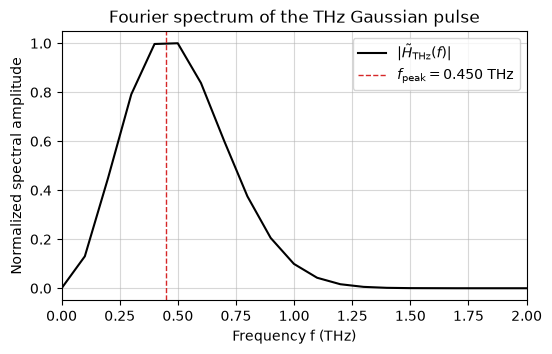

In [14]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(positive_freqlist, spectral_amplitude_normalized, color="black", linewidth=1.5,
        label=r"$|\tilde{H}_{\mathrm{THz}}(f)|$")

# For a second-derivative Gaussian, the analytic spectral maximum is sqrt(2)/(2*pi*sigma).
f_peak_analytic = np.sqrt(2) / (2 * np.pi * sigma)
ax.axvline(f_peak_analytic, color="tab:red", linestyle="--", linewidth=1,
           label=rf"$f_{{\mathrm{{peak}}}}={f_peak_analytic:.3f}$ THz")

ax.set_xlim([0,2])
ax.set_xlabel("Frequency f (THz)")
ax.set_ylabel("Normalized spectral amplitude")
ax.set_title("Fourier spectrum of the THz Gaussian pulse")
ax.grid(alpha=0.5)
ax.legend()

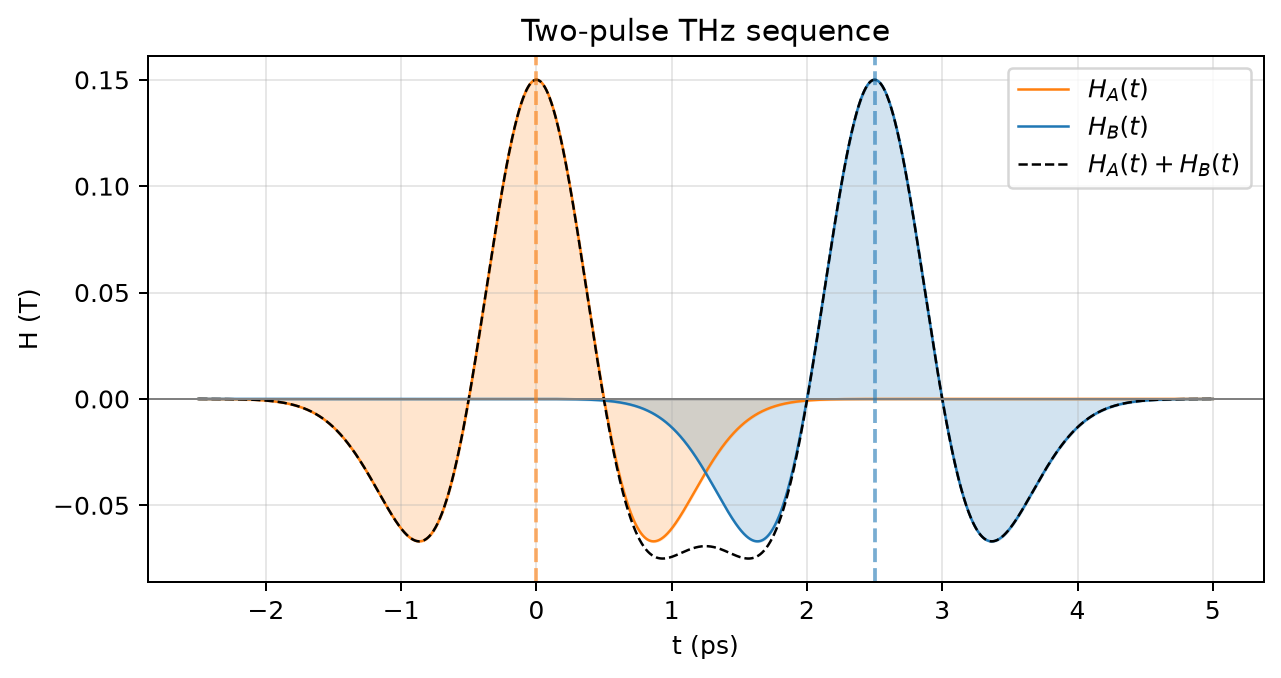

In [8]:
# Plot a two-pulse THz sequence directly (no plotting function).
pulse_func = d2gdt2_pulse
sigma = 0.5
tau_delay = 5.0 * sigma  # ps; pulse A is centred at tau_delay and pulse B at 0 ps

pulse_params = {
    "A": {
        "shape_params": {"t0": 0.0, "sigma": sigma, "h_peak": 0.15},
        "polarization": np.array([1.0, 0.0, 0.0]),  # a axis
        "state": "on",
    },
    "B": {
        "shape_params": {"t0": tau_delay, "sigma": sigma, "h_peak": 0.15},
        "polarization": np.array([1.0, 0.0, 0.0]),  # a axis
        "state": "on",
    },
}

sigma_A = pulse_params["A"]["shape_params"]["sigma"]
sigma_B = pulse_params["B"]["shape_params"]["sigma"]
t0_A = pulse_params["A"]["shape_params"]["t0"]
t0_B = pulse_params["B"]["shape_params"]["t0"]
tlist = np.linspace(min(t0_A - 5*sigma_A, t0_B - 5*sigma_B),
                    max(t0_A + 5*sigma_A, t0_B + 5*sigma_B), 2000)

h_A = pulse_func(tlist, **pulse_params["A"]["shape_params"])
h_B = pulse_func(tlist, **pulse_params["B"]["shape_params"])

e_A = pulse_params["A"]["polarization"] / np.linalg.norm(pulse_params["A"]["polarization"])
e_B = pulse_params["B"]["polarization"] / np.linalg.norm(pulse_params["B"]["polarization"])
H_A = h_A[:, None] * e_A
H_B = h_B[:, None] * e_B
H_total = H_A + H_B

# Plot the field projected on this axis; use [1, 0, 0] for the a axis.
plot_axis = np.array([1.0, 0.0, 0.0])
plot_axis = plot_axis / np.linalg.norm(plot_axis)
H_A_plot = H_A @ plot_axis
H_B_plot = H_B @ plot_axis
H_total_plot = H_total @ plot_axis

fig, ax = plt.subplots(figsize=(8, 3.8), dpi=180)
ax.fill_between(tlist, H_A_plot, 0, color="tab:orange", alpha=0.20)
ax.fill_between(tlist, H_B_plot, 0, color="tab:blue", alpha=0.20)
ax.plot(tlist, H_A_plot, color="tab:orange", linewidth=1.0, label=r"$H_A(t)$")
ax.plot(tlist, H_B_plot, color="tab:blue", linewidth=1.0, label=r"$H_B(t)$")
ax.plot(tlist, H_total_plot, color="black", linestyle="--", linewidth=1.0, label=r"$H_A(t)+H_B(t)$")
ax.axhline(0, color="gray", linewidth=0.8)
ax.axvline(t0_A, color="tab:orange", linestyle="--", alpha=0.6)
ax.axvline(t0_B, color="tab:blue", linestyle="--", alpha=0.6)
ax.set_xlabel("t (ps)")
ax.set_ylabel("H (T)")
ax.set_title("Two-pulse THz sequence")
ax.grid(alpha=0.3)
ax.legend()

###  Landau–Lifshitz–Gilbert (LLG) equation
$$ \frac{d \mathbf{S}_i}{dt} = - \frac{\gamma_0}{1+\alpha^2}\left[ \mathbf{S}_i\times \mathbf{H}^{\text{eff}}_i + \frac{\alpha}{|\mathbf{S}_i|}\mathbf{S}_i\times\left( \mathbf{S}_i \times \mathbf{H}^{\text{eff}}_i\right)\right] \\
=\frac{1}{1+\alpha^2}\left[ (\gamma_0\mathbf{H}^{\text{eff}}_i)\times\mathbf{S}_i  + \frac{\alpha}{|\mathbf{S}_i|}\mathbf{S}_i\times\left(  (\gamma_0\mathbf{H}^{\text{eff}}_i)\times \mathbf{S}_i\right)\right]
$$

- By observation, we can know that $|\mathbf{S}_1|^2$ and $|\mathbf{S}_2|^2$ are invariant with time, so for each spin, there are only two independent components, and we can take $(S_{1b},S_{1c},S_{2b},S_{2c})$ since for both spins, their largest component is either in the +a direction ( $\mathbf{S}_1$ ) or in the -a direction ( $\mathbf{S}_2$ )

- By observation again, we can see the term 
$(\gamma_0\mathbf{H}^{\text{eff}}_i)\times\mathbf{S}_i$ is linear in $\mathbf{S}_i$ 
while the term 
$\mathbf{S}_i\times\left(  (\gamma_0\mathbf{H}^{\text{eff}}_i)\times \mathbf{S}_i\right)$
is quadratic in $\mathbf{S}_i$.

- There are some special cases for the LLG equation. 
  - if no damping $\alpha = 0$
    - then the evolution of two spins are purely coherent, the memory won't extinguish.
    - if the initial two-spin configuration have a small fluctuation from the ground state, then how the two spins evolve with the time ?
  - if damping $\alpha \neq 0$, then the two spins will finally come to the ground state ( canted antiferromagnetic ), this process is irreversible.

In [10]:
# this function is to update the S1 and S2 vectors at each time step from the solutions (S1b,S1c,S2b,S2c) at the last time step.
# solution : sol = [S1b, S1c, S2b, S2c].
# S1a is positive and S2a is negative, consistent with the antiferromagnetic ground state.
def update_S1S2(sol, Stot):
    S1b, S1c, S2b, S2c = np.asarray(sol, dtype=float)
    S1a_sq = Stot**2 - S1b**2 - S1c**2
    S2a_sq = Stot**2 - S2b**2 - S2c**2

    tolerance = 1e-12 * Stot**2
    if S1a_sq < -tolerance:
        raise ValueError("The S1a exceed the Stot")
    if S2a_sq < -tolerance:
        raise ValueError("The S2a exceed the Stot")

    S1a =  np.sqrt(max(S1a_sq, 0.0)) # S1a is positive
    S2a = -np.sqrt(max(S2a_sq, 0.0)) # S2a is negative
    S1 = np.array([S1a, S1b, S1c])
    S2 = np.array([S2a, S2b, S2c])
    
    return S1, S2

# alpha : damping parameter
# pulse_func(t, **shape_params) returns the scalar temporal field amplitude.
def LLG_S1S2_dynamics(t, sol, Ham_params, alpha, pulse_params, pulse_func):
    """
        Four-component LLG RHS compatible with scipy.integrate.solve_ivp.
    """
    S1, S2 = update_S1S2(sol, Ham_params["Stot"])
    H1_internal, H2_internal = effective_fields_woH(S1, S2, Ham_params)
    
    H_external = two_THz_pulses(t, pulse_params, pulse_func)

    def llg(S, H_eff):
        precession = np.cross(H_eff, S)
        damping = np.cross(S, precession) / Ham_params["Stot"]
        return 1 / (1 + alpha**2) * (precession + alpha * damping)

    dS1_dt = llg(S1, H1_internal + H_external)
    dS2_dt = llg(S2, H2_internal + H_external)

    # Only the independent b and c components are integrated.
    return np.array([dS1_dt[1], dS1_dt[2], dS2_dt[1], dS2_dt[2]])

### Baseline Simulation : A off & B off
In this baseline simulation, we turn off both pulse A and pulse B, and also set the two spins in their equilibrium state, characterized by angle $\beta_0$

In fact, we can use arbitrary angles, and when the angle is not $\beta_0$, the system will approach to the equilibrium state because of the damping effect described by the phenomenological parameter $\alpha$.

In [26]:
# Baseline LLG simulation: both pulses are off, so this computes M0(t) = S1(t) + S2(t).
alpha = 0.01
time_list = np.linspace(0.0, 20.0, 2000)  # ps

# Equilibrium canted AFM configuration for S1a > 0 and S2a < 0.
nn = Ham_params["nn"]
Jex = Ham_params["Jex"]
Db = Ham_params["Dvec"][1]
Ka, _, Kc = Ham_params["Kvec"]
beta0 = 0.5 * np.arctan2(nn * Db, nn * Jex + Ka - Kc)
#
S1_eq = Ham_params["Stot"] * np.array([np.cos(beta0/2), 0.0, np.sin(beta0/2)])
S2_eq = Ham_params["Stot"] * np.array([-np.cos(beta0/2), 0.0, np.sin(beta0/2)])
y0_off = np.array([S1_eq[1], S1_eq[2], S2_eq[1], S2_eq[2]])

# Keep pulse shapes and polarizations, but switch both pulses off.
pulse_params_off = {
    label: {
        "shape_params": dict(pulse["shape_params"]),
        "polarization": np.array(pulse["polarization"], copy=True),
        "state": "off",
    }
    for label, pulse in pulse_params.items()
}

sol_off = solve_ivp(
    LLG_S1S2_dynamics,
    (time_list[0], time_list[-1]),
    y0_off,
    t_eval=time_list,
    args=(Ham_params, alpha, pulse_params_off, pulse_func),
    method="DOP853",
    rtol=1e-9,
    atol=1e-11,
    max_step=0.02,
)

S1_off = np.empty((time_list.size, 3))
S2_off = np.empty((time_list.size, 3))
for index, state in enumerate(sol_off.y.T):
    S1_off[index], S2_off[index] = update_S1S2(state, Ham_params["Stot"])

M_off = S1_off + S2_off

Maximum |M(t) - M(0)|: 4.408e-02


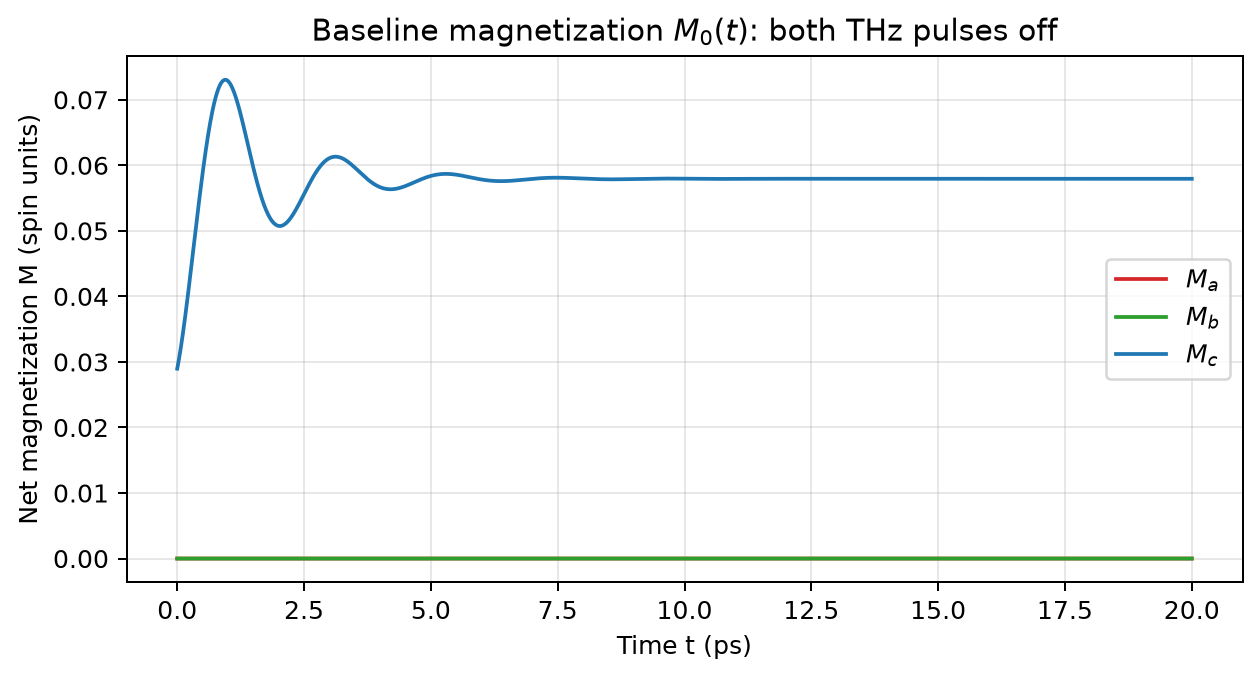

In [27]:
fig, ax = plt.subplots(figsize=(8, 3.8), dpi=180)
ax.plot(time_list, M_off[:, 0], color="tab:red", label=r"$M_a$")
ax.plot(time_list, M_off[:, 1], color="tab:green", label=r"$M_b$")
ax.plot(time_list, M_off[:, 2], color="tab:blue", label=r"$M_c$")
ax.set_xlabel("Time t (ps)")
ax.set_ylabel("Net magnetization M (spin units)")
ax.set_title(r"Baseline magnetization $M_0(t)$: both THz pulses off")
ax.grid(alpha=0.3)
ax.legend()

print(f"Maximum |M(t) - M(0)|: {np.max(np.abs(M_off - M_off[0])):.3e}")

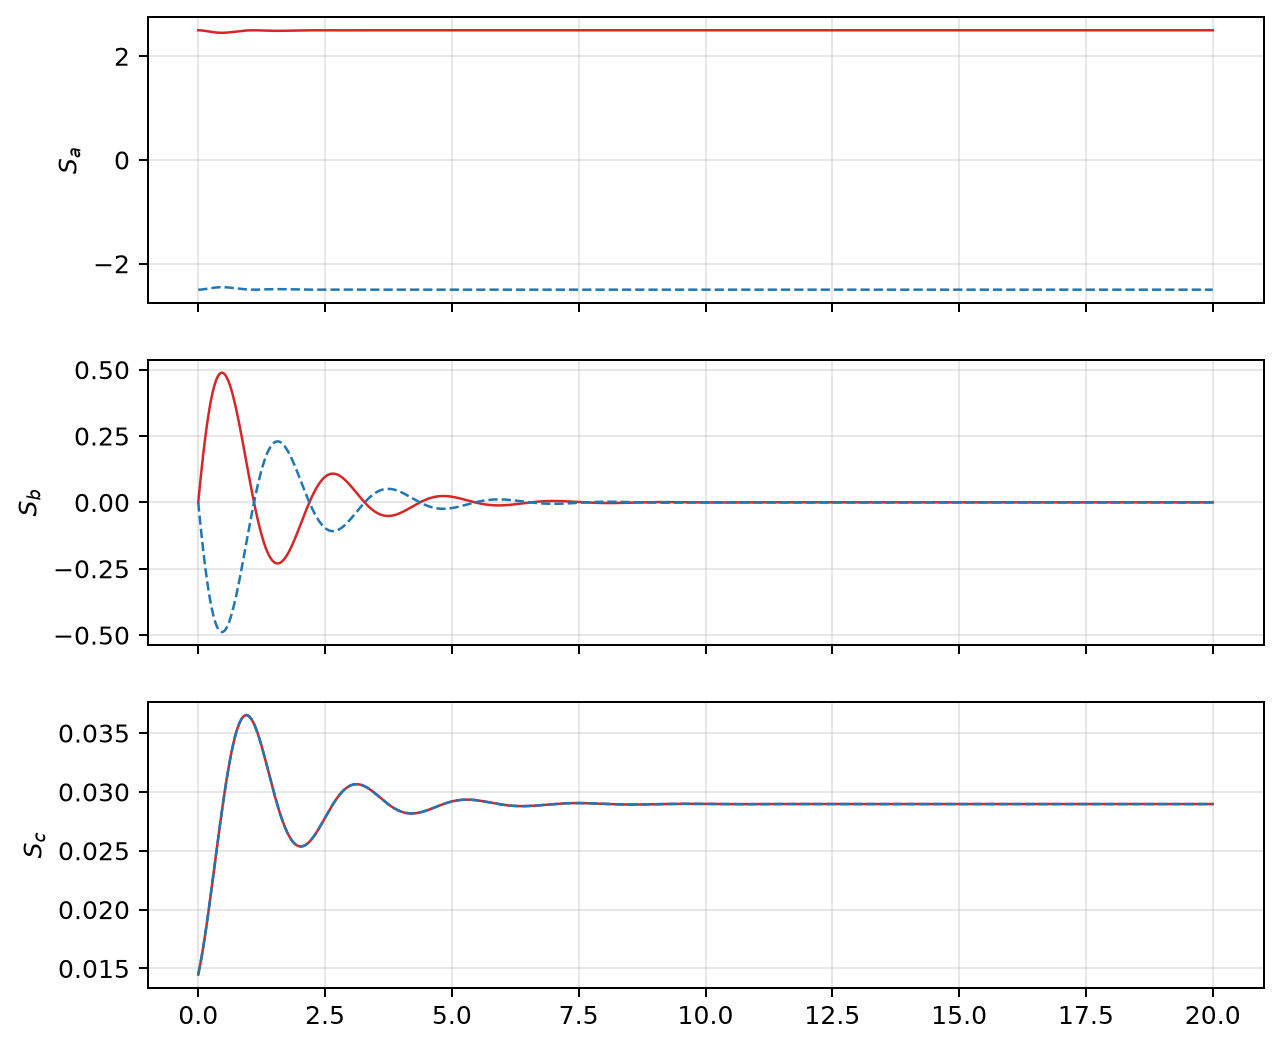

In [28]:
# Individual sublattice-spin trajectories for the both-pulses-off simulation.
fig, axes = plt.subplots(3, 1, figsize=(8, 7), dpi=180, sharex=True)
component_labels = ["a", "b", "c"]

for component, ax in enumerate(axes):
    ax.plot(time_list, S1_off[:, component], color="tab:red", linewidth=1.0, label=r"$S_1$")
    ax.plot(time_list, S2_off[:, component], color="tab:blue", linestyle="--", linewidth=1.0, label=r"$S_2$")
    ax.set_ylabel(rf"$S_{{{component_labels[component]}}}$")
    ax.grid(alpha=0.3)

# axes[0].set_title(r"Individual sublattice spins: both THz pulses off")
# axes[0].legend()
# axes[-1].set_xlabel("Time t (ps)")
# fig.tight_layout()

# print(f"max |S1(t)-S1(0)| = {np.max(np.abs(S1_off - S1_off[0])):.3e}")
# print(f"max |S2(t)-S2(0)| = {np.max(np.abs(S2_off - S2_off[0])):.3e}")

Maximum spin-length error: 6.217e-15


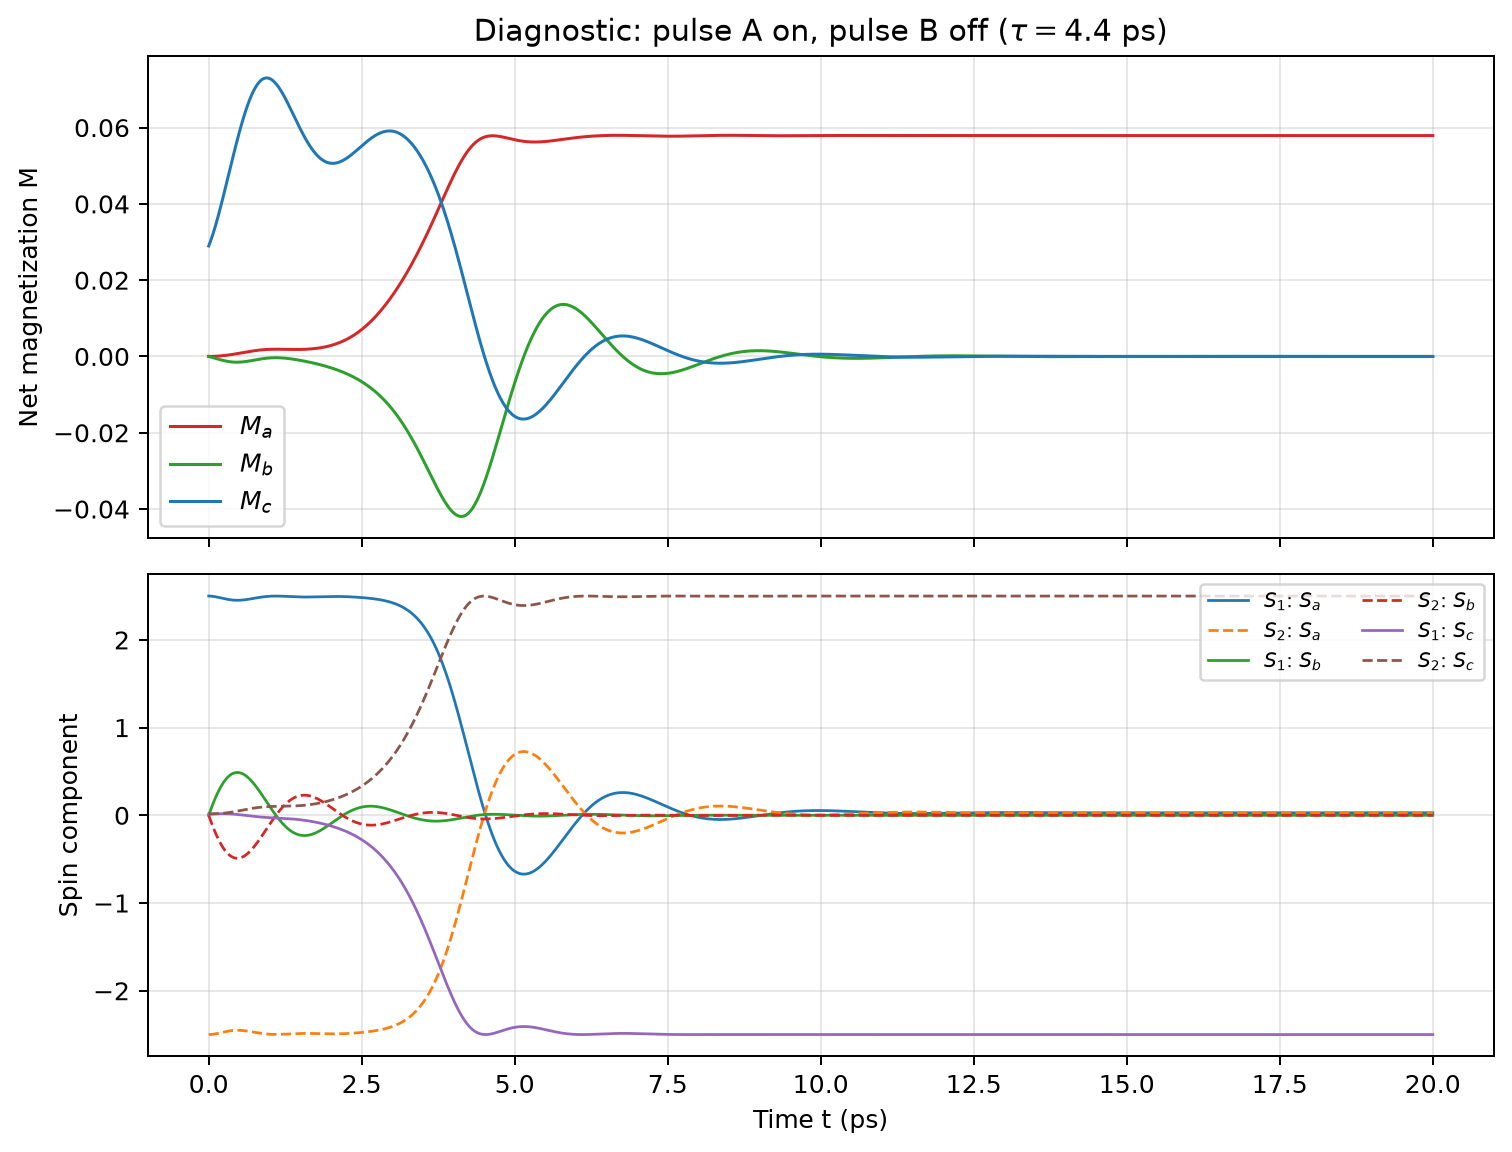

In [30]:
# Four pulse-chopping configurations used to construct a 2D-THz nonlinear signal.
# We use tau = 4.4 ps, the fixed interpulse delay used for the LLG dynamics
# in the 2024 paper.  Pulse A is centred at t = 0 and pulse B at t = tau_delay.
tau_delay_article = 4.4  # ps

# The four-variable representation fixes S1a > 0 and S2a < 0.  A strong
# THz kick can cross that coordinate boundary, so use the equivalent full
# six-component LLG form here.  This has no fixed-hemisphere restriction.
def LLG_S1S2_full_dynamics(t, state, Ham_params, alpha, pulse_params, pulse_func):
    S1, S2 = state[:3], state[3:]
    H1_internal, H2_internal = effective_fields_woH(S1, S2, Ham_params)
    H_external = two_THz_pulses(t, pulse_params, pulse_func)

    def llg(S, H_eff):
        precession = np.cross(H_eff, S)
        damping = np.cross(S, precession) / Ham_params['Stot']
        return (precession + alpha * damping) / (1.0 + alpha**2)

    return np.concatenate((llg(S1, H1_internal + H_external),
                           llg(S2, H2_internal + H_external)))

# Work on independent copies: the global pulse_params dictionary is not changed.
pulse_params_tau = {
    label: {
        'shape_params': dict(pulse['shape_params']),
        'polarization': np.array(pulse['polarization'], copy=True),
        'state': 'on',
    }
    for label, pulse in pulse_params.items()
}
pulse_params_tau['A']['shape_params']['t0'] = 0.0
pulse_params_tau['B']['shape_params']['t0'] = tau_delay_article

# Diagnostic run: pulse A on and pulse B off.
# Both spin sublattices start from exactly the same initial state as the baseline run.
pulse_params_Aon_Boff = {
    label: {
        'shape_params': dict(pulse['shape_params']),
        'polarization': np.array(pulse['polarization'], copy=True),
        'state': pulse['state'],
    }
    for label, pulse in pulse_params_tau.items()
}
pulse_params_Aon_Boff['A']['state'] = 'on'
pulse_params_Aon_Boff['B']['state'] = 'off'

S1_initial, S2_initial = update_S1S2(y0_off, Ham_params['Stot'])
state0_four_cases = np.concatenate((S1_initial, S2_initial))
sol_Aon_Boff = solve_ivp(
    LLG_S1S2_full_dynamics,
    (time_list[0], time_list[-1]),
    state0_four_cases,
    t_eval=time_list,
    args=(Ham_params, alpha, pulse_params_Aon_Boff, pulse_func),
    method='DOP853', rtol=1e-9, atol=1e-11, max_step=0.02,
)
if not sol_Aon_Boff.success:
    raise RuntimeError(sol_Aon_Boff.message)

S1_Aon_Boff = sol_Aon_Boff.y[:3].T
S2_Aon_Boff = sol_Aon_Boff.y[3:].T
M_Aon_Boff = S1_Aon_Boff + S2_Aon_Boff

fig, axes = plt.subplots(2, 1, figsize=(8.5, 6.5), dpi=180, sharex=True)
for component, (color, label) in enumerate(zip(('tab:red', 'tab:green', 'tab:blue'),
                                                (r'$M_a$', r'$M_b$', r'$M_c$'))):
    axes[0].plot(time_list, M_Aon_Boff[:, component], color=color, lw=1.2, label=label)
axes[0].set_ylabel('Net magnetization M')
axes[0].set_title(r'Diagnostic: pulse A on, pulse B off ($\tau=4.4$ ps)')
axes[0].grid(alpha=0.3)
axes[0].legend()

for component, label in enumerate((r'$S_a$', r'$S_b$', r'$S_c$')):
    axes[1].plot(time_list, S1_Aon_Boff[:, component], lw=1.1, label=rf'$S_1$: {label}')
    axes[1].plot(time_list, S2_Aon_Boff[:, component], '--', lw=1.1, label=rf'$S_2$: {label}')
axes[1].set_xlabel('Time t (ps)')
axes[1].set_ylabel('Spin component')
axes[1].grid(alpha=0.3)
axes[1].legend(ncol=2, fontsize=8)
fig.tight_layout()

spin_length_error = max(np.max(np.abs(np.linalg.norm(S1_Aon_Boff, axis=1) - Ham_params['Stot'])),
                        np.max(np.abs(np.linalg.norm(S2_Aon_Boff, axis=1) - Ham_params['Stot'])))
print(f'Maximum spin-length error: {spin_length_error:.3e}')
